# HW3
## Load Data


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score




In [3]:
data = pd.read_csv("04-evaluation/course_lead_scoring_2026.csv")
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Q1

In [4]:
data.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
numerical_features = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']
categorical_features = ['lead_source','industry','employment_status','location']

data[categorical_features] = data[categorical_features].fillna('NA')
data[numerical_features] = data[numerical_features].fillna(0)

In [6]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [7]:
y_train = df_train.converted.values
y_val = df_val.converted.values 
y_test = df_test.converted.values

In [8]:
for fea in ["lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"]:
    auc = roc_auc_score(y_train, df_train[fea])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[fea])

    print(f"{fea}: {auc:.4f}")

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


## Q2

In [9]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [10]:
dicts_train = df_train[categorical_features + numerical_features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(dicts_train)

In [11]:
dicts_val = df_val[categorical_features + numerical_features].to_dict(orient='records')
X_val = dv.transform(dicts_val)

In [12]:
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

roc_auc_score(y_val,y_pred)
# sign_decision = (y_pred >= 0.5)
# round((sign_decision == y_val).mean(),2)

0.7318222288173319

## Q3

In [13]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

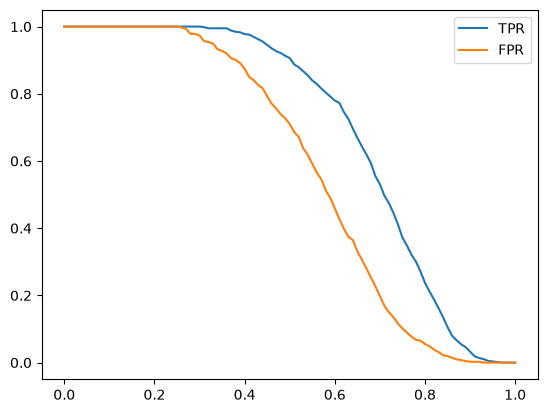

In [15]:
import matplotlib.pyplot as plt

plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

## Q4

In [18]:
df_scores['f1'] = 2 * (df_scores.fpr * df_scores.tpr) / (df_scores.fpr + df_scores.tpr)

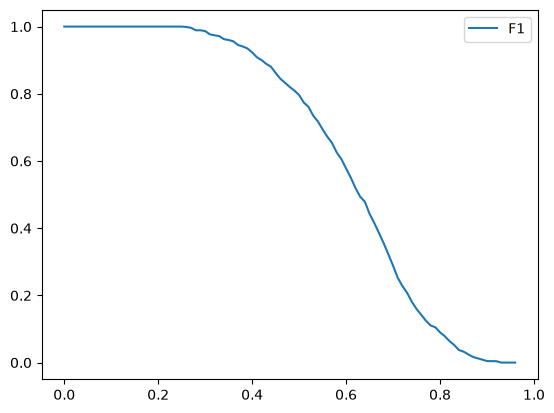

In [20]:
plt.plot(df_scores.threshold, df_scores['f1'], label='F1')
# plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

## Q5

In [24]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [22]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical_features + numerical_features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [ ]:
def predict(df, dv, model):
    dicts = df[categorical_features + numerical_features].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [36]:
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=1)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

round(np.std(scores),3)

np.float64(0.007)

## Q6

In [39]:
from tqdm.auto import tqdm

C_list = [0.000001, 0.001, 1]

for C in tqdm(C_list):
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
            df_train = df_full_train.iloc[train_idx]
            df_val = df_full_train.iloc[val_idx]

            y_train = df_train.converted.values
            y_val = df_val.converted.values

            dv, model = train(df_train, y_train, C=C)
            y_pred = predict(df_val, dv, model)

            auc = roc_auc_score(y_val, y_pred)
            scores.append(auc)

    print('C=%s Mean & Dev=%.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 Mean & Dev=0.617 +- 0.019
C=0.001 Mean & Dev=0.749 +- 0.010
C=1 Mean & Dev=0.732 +- 0.007
